In [1]:
import warnings; warnings.filterwarnings("ignore")
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
from credit_risk import config as C, data as D, features as F, scorecard as S, models as M
from credit_risk import calibration as CAL, business as B, fairness as FAIR, stability as ST
R = lambda s: json.load(open(C.REPORTS / f"metrics_{s}.json"))
def app():
    t = pd.read_parquet(C.ROOT / "data/synthetic/application_train.parquet")  # use data/raw + D.read_table for real data
    return F.engineer_application(D.clean_application(t)), t


# 06 - Business cut-off and fairness
Economics are **illustrative assumptions**.

In [2]:
m = R('A'); pd.DataFrame(m['business']['assumptions'], index=[0]).T

,0
margin_rate,0.1
lgd,0.7
cost_per_application,0.0


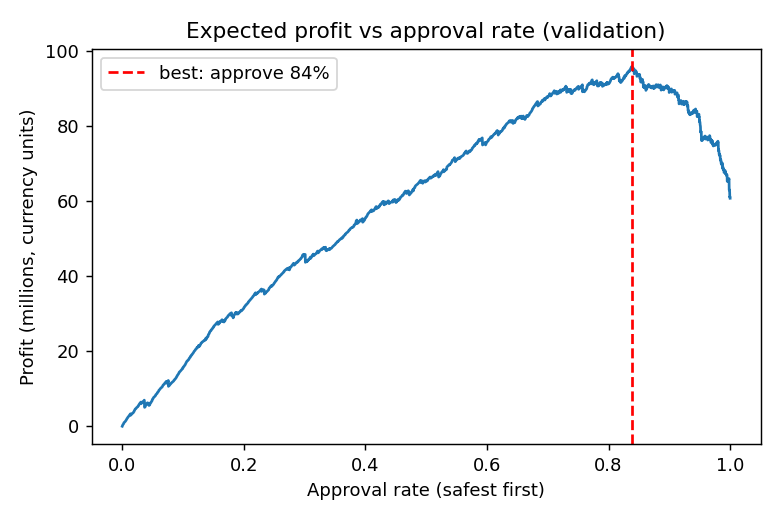

{'profit': 87535500.0, 'approval_rate': 0.8375, 'bad_rate_approved': 0.0617910447761194} {'approve_all': 67674300.0, 'approve_top_70pct': 90650800.0}


In [3]:
display(Image(str(C.FIGURES / 'profit_A.png'))); print(m['business']['test'], m['business']['baselines_test'])

In [4]:
pd.DataFrame(m['business']['sensitivity'])

,lgd_change,margin_change,lgd,margin,best_approval_rate,best_pd_cutoff,profit
0,-0.2,-0.2,0.56,0.08,0.83825,0.136067,76698400.0
1,-0.2,0.0,0.56,0.10,0.83825,0.136067,111498820.0
2,-0.2,0.2,0.56,0.12,0.89600,0.163533,147572480.0
3,0.0,-0.2,0.70,0.08,0.83825,0.136067,61072580.0
4,0.0,0.0,0.70,0.10,0.83825,0.136067,95873000.0
5,0.0,0.2,0.70,0.12,0.83825,0.136067,130673420.0
6,0.2,-0.2,0.84,0.08,0.71075,0.099531,49425640.0
7,0.2,0.0,0.84,0.10,0.83825,0.136067,80247180.0
8,0.2,0.2,0.84,0.12,0.83825,0.136067,115047600.0


In [5]:
for g, f in m['fairness'].items():
    print(g, f['gaps']); display(pd.DataFrame(f['table']).round(3))

gender {'approval_rate_gap': 0.0018671205446094685, 'disparate_impact_ratio': 0.9977735106593792, 'false_decline_gap': 0.006680596327672594, 'false_approve_gap': 0.02427068388330944, 'mean_score_gap': 0.06001868361340712, 'four_fifths_rule_flag': False}


,group,n,default_rate,approval_rate,bad_rate_among_approved,false_decline_rate,false_approve_rate,mean_pd,mean_score
0,F,2603,0.078,0.837,0.060,0.147,0.642,0.081,563.996
1,M,1394,0.088,0.839,0.065,0.140,0.618,0.081,563.936


age_band {'approval_rate_gap': 0.03980501033057848, 'disparate_impact_ratio': 0.9530410938035572, 'false_decline_gap': 0.04054338202744576, 'false_approve_gap': 0.09134615384615385, 'mean_score_gap': 0.9211773267754779, 'four_fifths_rule_flag': False}


,group,n,default_rate,approval_rate,bad_rate_among_approved,false_decline_rate,false_approve_rate,mean_pd,mean_score
0,30-39,1110,0.082,0.840,0.063,0.143,0.648,0.081,564.099
1,40-49,1376,0.088,0.845,0.064,0.133,0.620,0.081,564.039
2,50-59,774,0.061,0.836,0.046,0.151,0.638,0.081,563.861
3,60+,256,0.062,0.848,0.041,0.133,0.562,0.082,564.423
4,<30,484,0.107,0.808,0.087,0.174,0.654,0.083,563.502


family_status {'approval_rate_gap': 0.07477541680604638, 'disparate_impact_ratio': 0.9143101590017667, 'false_decline_gap': 0.07487576563041719, 'false_approve_gap': 0.1837044534412956, 'mean_score_gap': 3.0840798091411443, 'four_fifths_rule_flag': False}


,group,n,default_rate,approval_rate,bad_rate_among_approved,false_decline_rate,false_approve_rate,mean_pd,mean_score
0,Civil marriage,369,0.079,0.873,0.062,0.112,0.690,0.076,566.006
1,Married,2578,0.081,0.836,0.058,0.143,0.606,0.082,563.384
2,Separated,283,0.074,0.866,0.057,0.118,0.667,0.076,565.934
3,Single / not married,559,0.089,0.798,0.072,0.187,0.640,0.084,563.469
4,Widow,211,0.090,0.858,0.083,0.135,0.789,0.076,566.468
